# CCS 246 — Introduction to Artificial Intelligence
## Final Project: Autonomous Urban Emergency Dispatch & Routing System

| Members |Name |
|---|---|
| 1 | Alconada, Karl Kenth |
| 2 | Besana, Sean Benedict |
| 3 | Escorpiso, John Chrizper |
| 4 | Labrador Jr., William |
| 5 | Saraet, Nicholas Robert |

---

## Table of Contents

1. [Problem Context](#section-1)
2. [System Architecture & Module Integration](#section-2)
3. [Module 1 — Dynamic Route Planning & Heuristic Analysis](#section-3)
4. [Module 2 — Response Hub Location Optimization](#section-4)
5. [Module 3 — Tactical Adversarial Hazard Navigation](#section-5)
6. [Module 4 — Automated Dispatch Safety Verification Engine](#section-6)

---
## Section 1: Problem Context <a id='section-1'></a>

### 1.1 Disaster Response Challenges

Metro City has been struck by severe storm flooding, causing widespread road closures, traffic gridlock, and unpredictable hazards across the urban grid. Emergency services — ambulances and fire engines — are severely hampered by the inability of the existing static dispatch system to account for real-time road conditions. Flooded blocks render entire road segments completely impassable, while heavily congested roads multiply travel times by a factor of three to eight. The central dispatch team can no longer rely on pre-computed lookup tables and requires a dynamic, intelligent routing and allocation framework.

### 1.2 Project Goals

This project transitions Metro City Emergency Services from a legacy static lookup system to a four-module AI dispatch framework:

- **Module 1 — Dynamic Route Planning:** An A* search algorithm that navigates emergency vehicles across a weighted 50×50 grid, accounting for congestion and impassable flood zones.
- **Module 2 — Hub Location Optimization:** A weighted p-median clustering algorithm that repositions four response hubs to minimize average weighted response delay to 25 known incident hotspots.
- **Module 3 — Adversarial Hazard Navigation:** A Minimax agent with alpha-beta pruning that routes an ambulance against a dynamic hazard agent expanding blockages each turn.
- **Module 4 — Safety Verification Engine:** A forward-chaining rule engine that evaluates all safety constraints before authorizing any vehicle dispatch.

---
## Section 2: System Architecture & Module Integration <a id='section-2'></a>

### 2.1 Global System Pipeline

The four modules form a sequential dispatch pipeline. A request enters the Safety Engine first; only approved requests proceed to hub assignment, then route planning, then real-time adversarial navigation.

```
Dispatch Request
      |
      v
[Module 4: Safety Engine] --> BLOCKED (stops here if any rule fails)
      |
   APPROVED
      |
      v
[Module 2: Hub Optimizer] --> assigns nearest optimized hub to incident
      |
      v
[Module 1: A* Router]     --> computes optimal weighted path S -> G
      |
      v
[Module 3: Minimax Agent] --> navigates in real-time around hazard expansion
      |
      v
Vehicle arrives at incident site
```

### 2.2 NetworkX Data Model

The city is represented as a 50×50 directed grid graph where each cell `(x, y)` is a node and each traversable edge carries a travel cost:

| Road Type | Edge Cost |
|---|---|
| Clear Road | c = 1.0 |
| Congested Road | c ∈ [3.0, 8.0] |
| Flooded Block | c = ∞ (impassable) |

Each hotspot node additionally stores a priority weight `wi ∈ {1, 3}`. Hazard states are tracked as a set of blocked coordinates that grows each turn during Module 3 execution. Figure 1 (pipeline diagram) and Figure 2 (grid layout) are produced by the code cells below.

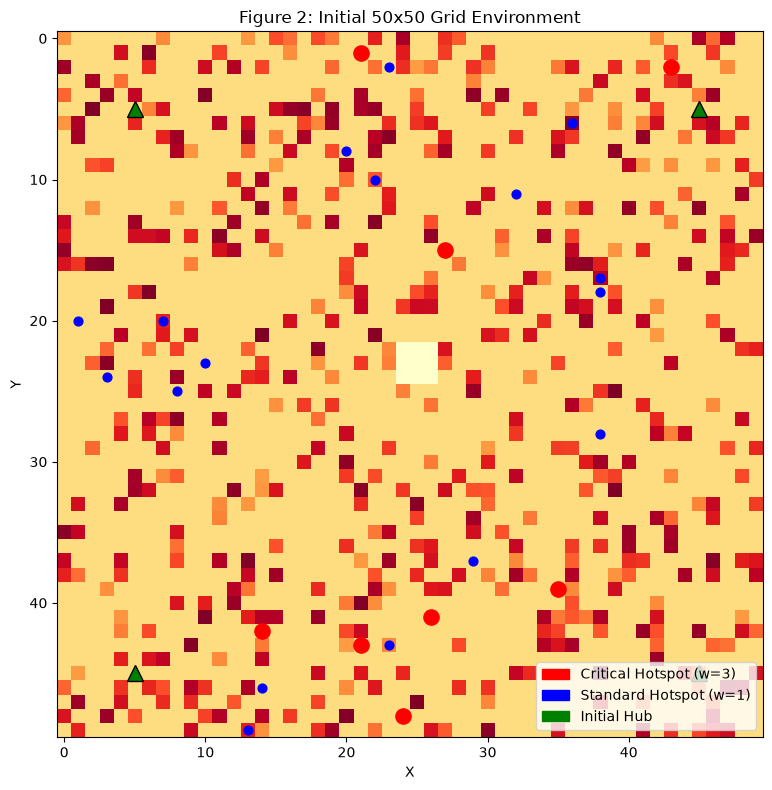

In [1]:
# Figure 2 — Initial Grid Environment Layout
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

GRID_SIZE = 50
FLOODED   = float('inf')

rng  = np.random.default_rng(42)
grid = np.ones((GRID_SIZE, GRID_SIZE), dtype=float)
for _ in range(600):
    x, y = rng.integers(0, GRID_SIZE, size=2)
    grid[y][x] = rng.uniform(3.0, 8.0)
flood_cells = [(24,22),(24,23),(24,24),(25,22),(25,23),(25,24),(26,22),(26,23),(26,24)]
for cx, cy in flood_cells:
    grid[cy][cx] = FLOODED

np.random.seed(42)
hotspots   = np.random.randint(0, GRID_SIZE, size=(25, 2))
priorities = np.random.choice([1, 3], size=25, p=[0.6, 0.4])
init_hubs  = np.array([[5,5],[45,5],[5,45],[45,45]])

display = np.where(grid == FLOODED, -1, grid)
plt.figure(figsize=(8, 8))
plt.imshow(display, cmap='YlOrRd', origin='upper')
for i, (hx, hy) in enumerate(init_hubs):
    plt.plot(hx, hy, '^', color='green', markersize=12, markeredgecolor='black')
for i, (sx, sy) in enumerate(hotspots):
    color = 'red' if priorities[i] == 3 else 'blue'
    plt.scatter(sx, sy, s=priorities[i]*40, color=color, zorder=5)
p1 = mpatches.Patch(color='red',   label='Critical Hotspot (w=3)')
p2 = mpatches.Patch(color='blue',  label='Standard Hotspot (w=1)')
p3 = mpatches.Patch(color='green', label='Initial Hub')
plt.legend(handles=[p1,p2,p3], loc='lower right')
plt.title('Figure 2: Initial 50x50 Grid Environment')
plt.xlabel('X'); plt.ylabel('Y')
plt.tight_layout(); plt.show()

---
## Section 3: Module 1 — Dynamic Route Planning & Heuristic Analysis <a id='section-3'></a>

### 3.1 Search Algorithm Design

A* search is an informed best-first search algorithm that finds the least-cost path from a start node `S` to a goal node `G` using the evaluation function:

$$f(n) = g(n) + h(n)$$

Where:
- `g(n)` — the actual accumulated cost from the start node to node `n`.
- `h(n)` — the heuristic estimate of the remaining cost from `n` to the goal.

The algorithm maintains an **open set** (priority queue ordered by `f(n)`) and a **closed set** (already-evaluated nodes). At each step, the node with the lowest `f(n)` is expanded. Neighbors are added to the open set only if a cheaper path to them is discovered.

In this implementation, edge weights correspond to road traversal costs: `c = 1.0` for clear roads, `c ∈ [3.0, 8.0]` for congested roads, and `c = ∞` (impassable) for flooded blocks.

### 3.2 Heuristic Comparison

Two heuristics are evaluated:

**h1 — Manhattan Distance:**
$$h_1(n) = |x_n - x_G| + |y_n - y_G|$$
Admissible (never overestimates), since the minimum possible edge cost is 1.0. Guarantees optimal path cost.

**h2 — Weighted Manhattan Distance:**
$$h_2(n) = 1.2 \times (|x_n - x_G| + |y_n - y_G|)$$
Inadmissible — may overestimate cost, so optimality is not guaranteed. However, the inflated heuristic causes A* to expand fewer nodes and run faster, making it preferable in time-critical dispatch scenarios where a near-optimal path is acceptable.

### 3.3 Experimental Findings

The code below runs A* with both heuristics across three congestion densities (10%, 25%, 40%) and prints a comparison table. Figure 3 shows expanded nodes vs. optimal path side-by-side for h1 and h2.

Density    Heuristic             Nodes     Cost    Time(s)
----------------------------------------------------------
    10%     Manhattan              1975    98.00     0.0102
    10%     Weighted                115   100.00     0.0005
    25%     Manhattan              1634   101.27     0.0097
    25%     Weighted                151   103.27     0.0014
    40%     Manhattan              1331   105.27     0.0092
    40%     Weighted                198   105.39     0.0018


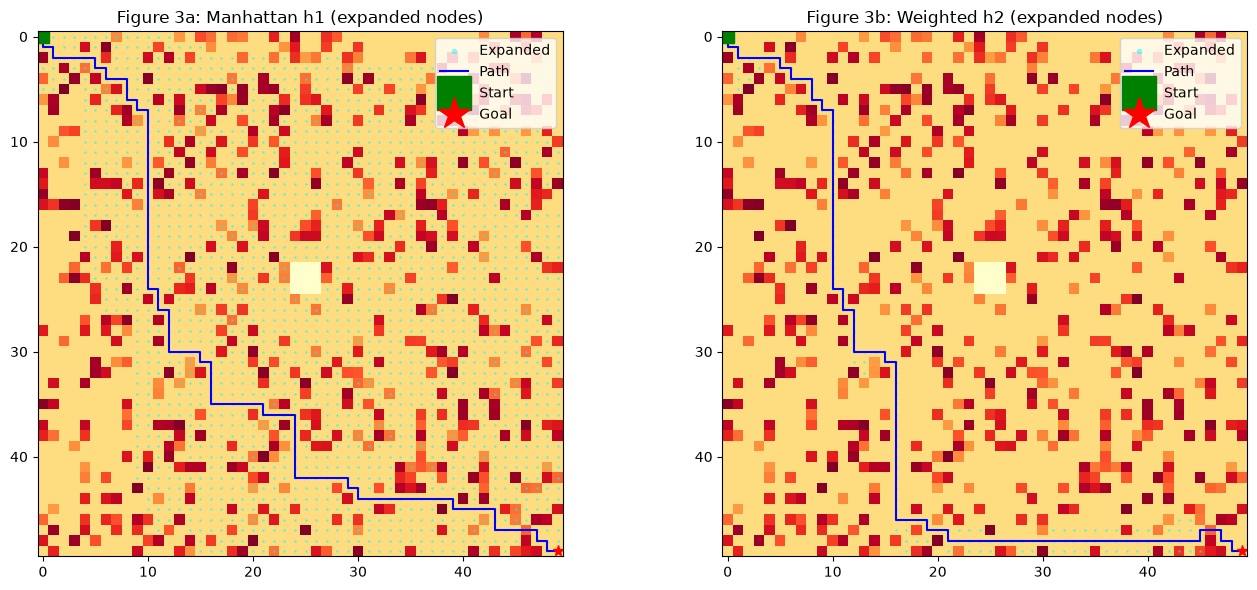

In [2]:
import heapq
import numpy as np
import matplotlib.pyplot as plt
import time

GRID_SIZE = 50
FLOODED   = float('inf')

def make_grid(congestion_pct: float, seed: int = 42) -> np.ndarray:
    """Build a GRID_SIZE x GRID_SIZE grid with given congestion percentage."""
    rng  = np.random.default_rng(seed)
    g    = np.ones((GRID_SIZE, GRID_SIZE), dtype=float)
    n    = int(GRID_SIZE**2 * congestion_pct)
    for _ in range(n):
        x, y = rng.integers(0, GRID_SIZE, size=2)
        g[y][x] = rng.uniform(3.0, 8.0)
    for cx, cy in [(24,22),(24,23),(24,24),(25,22),(25,23),(25,24),(26,22),(26,23),(26,24)]:
        g[cy][cx] = FLOODED
    return g

def manhattan(a: tuple, b: tuple) -> float:
    """Admissible Manhattan distance heuristic."""
    return abs(a[0]-b[0]) + abs(a[1]-b[1])

def weighted_manhattan(a: tuple, b: tuple) -> float:
    """Weighted (inadmissible) Manhattan distance heuristic."""
    return 1.2 * manhattan(a, b)

def astar(grid: np.ndarray, start: tuple, goal: tuple, heuristic) -> tuple:
    """A* search. Returns (path, cost, nodes_expanded, elapsed_time, closed_set)."""
    open_set = []
    heapq.heappush(open_set, (0.0, start))
    came_from = {}
    g      = {start: 0.0}
    closed = set()
    t0     = time.perf_counter()

    while open_set:
        _, cur = heapq.heappop(open_set)
        if cur in closed:
            continue
        closed.add(cur)
        if cur == goal:
            path = []
            while cur in came_from:
                path.append(cur); cur = came_from[cur]
            path.append(start); path.reverse()
            return path, g[goal], len(closed), time.perf_counter()-t0, closed
        x, y = cur
        for dx, dy in [(0,1),(0,-1),(1,0),(-1,0)]:
            nx, ny = x+dx, y+dy
            if 0 <= nx < GRID_SIZE and 0 <= ny < GRID_SIZE:
                cost = grid[ny][nx]
                if cost == FLOODED:
                    continue
                ng = g[cur] + cost
                nb = (nx, ny)
                if ng < g.get(nb, float('inf')):
                    came_from[nb] = cur
                    g[nb]         = ng
                    heapq.heappush(open_set, (ng + heuristic(nb, goal), nb))

    return None, float('inf'), len(closed), time.perf_counter()-t0, closed

START = (0, 0)
GOAL  = (49, 49)

# --- Congestion density comparison ---
print(f"{'Density':<10} {'Heuristic':<18} {'Nodes':>8} {'Cost':>8} {'Time(s)':>10}")
print('-' * 58)
for pct in [0.10, 0.25, 0.40]:
    g = make_grid(pct)
    for label, h in [('Manhattan', manhattan), ('Weighted', weighted_manhattan)]:
        path, cost, nodes, t, _ = astar(g, START, GOAL, h)
        print(f"{int(pct*100):>6}%     {label:<18} {nodes:>8} {cost:>8.2f} {t:>10.4f}")

# --- Figure 3: expanded nodes overlay ---
grid25 = make_grid(0.25)
path1, cost1, nodes1, time1, closed1 = astar(grid25, START, GOAL, manhattan)
path2, cost2, nodes2, time2, closed2 = astar(grid25, START, GOAL, weighted_manhattan)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, path, closed, title in zip(
        axes, [path1, path2], [closed1, closed2],
        ['Figure 3a: Manhattan h1 (expanded nodes)', 'Figure 3b: Weighted h2 (expanded nodes)']):
    display = np.where(grid25 == FLOODED, -1, grid25)
    ax.imshow(display, cmap='YlOrRd', origin='upper')
    if closed:
        ex, ey = zip(*closed)
        ax.scatter(ex, ey, s=1, color='cyan', alpha=0.4, label='Expanded')
    if path:
        px, py = zip(*path)
        ax.plot(px, py, 'b-', linewidth=1.5, label='Path')
    ax.plot(*START, 'gs', markersize=8, label='Start')
    ax.plot(*GOAL,  'r*', markersize=8, label='Goal')
    ax.set_title(title); ax.legend(markerscale=3)
plt.tight_layout(); plt.show()

---
## Section 4: Module 2 — Response Hub Location Optimization <a id='section-4'></a>

### 4.1 Facility Location Strategy

The hub placement problem is formulated as a **weighted p-median problem**: given N = 25 incident hotspots and K = 4 hubs, find hub positions that minimize the total weighted distance from every hotspot to its nearest hub.

The algorithm follows an iterative weighted centroid approach:
1. **Assignment step** — each hotspot is assigned to the nearest hub by Euclidean distance.
2. **Update step** — each hub is repositioned to the priority-weighted centroid of its assigned cluster.
3. Steps repeat until hub positions converge (movement < 1e-4 units).

### 4.2 Priority Multiplier Impact

Each hotspot carries a priority weight: `wi = 1` (Standard) or `wi = 3` (Critical). In the weighted centroid calculation, critical hotspots exert three times the pull on a hub's final position compared to standard ones. This causes hubs to shift noticeably toward dense clusters of critical incidents, reducing average weighted response delay for the highest-priority emergencies.

Final hub positions:
  Hub 1: (38.9, 10.8)
  Hub 2: (23.1, 42.8)
  Hub 3: (23.2, 7.6)
  Hub 4: (5.8, 22.4)


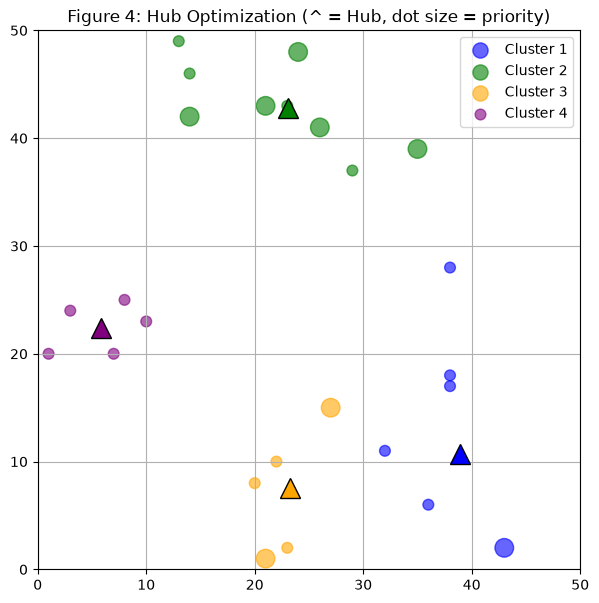

In [3]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
GRID_SIZE  = 50
N, K       = 25, 4
hotspots   = np.random.randint(0, GRID_SIZE, size=(N, 2)).astype(float)
priorities = np.random.choice([1, 3], size=N, p=[0.6, 0.4])

def weighted_pmedian(hotspots: np.ndarray, weights: np.ndarray, k: int, max_iter: int = 300) -> tuple:
    """Iterative weighted p-median hub placement. Returns (hubs, assignment)."""
    idx  = np.random.choice(len(hotspots), k, replace=False)
    hubs = hotspots[idx].copy().astype(float)
    for _ in range(max_iter):
        dists      = np.linalg.norm(hotspots[:,None,:] - hubs[None,:,:], axis=2)
        assignment = np.argmin(dists, axis=1)
        new_hubs   = np.zeros_like(hubs)
        for j in range(k):
            members = np.where(assignment == j)[0]
            if len(members) == 0:
                new_hubs[j] = hotspots[np.random.randint(len(hotspots))]
            else:
                new_hubs[j] = np.average(hotspots[members], axis=0, weights=weights[members])
        new_hubs = np.clip(new_hubs, 0, GRID_SIZE-1)
        if np.max(np.linalg.norm(new_hubs - hubs, axis=1)) < 1e-4:
            break
        hubs = new_hubs
    return hubs, assignment

hubs, assignment = weighted_pmedian(hotspots, priorities, K)
print('Final hub positions:')
for i, h in enumerate(hubs):
    print(f'  Hub {i+1}: ({h[0]:.1f}, {h[1]:.1f})')

# --- Figure 4 ---
colors = ['blue','green','orange','purple']
plt.figure(figsize=(7,7))
for j in range(K):
    members = np.where(assignment == j)[0]
    plt.scatter(hotspots[members,0], hotspots[members,1],
                s=priorities[members]*60, color=colors[j], alpha=0.6, label=f'Cluster {j+1}')
    plt.plot(*hubs[j], marker='^', color=colors[j], markersize=14, markeredgecolor='black')
plt.xlim(0, GRID_SIZE); plt.ylim(0, GRID_SIZE)
plt.title('Figure 4: Hub Optimization (^ = Hub, dot size = priority)')
plt.legend(); plt.grid(True); plt.show()

---
## Section 5: Module 3 — Tactical Adversarial Hazard Navigation <a id='section-5'></a>

### 5.1 Game Formulation

The scenario is modeled as a two-player zero-sum turn-based game on the 50×50 grid:

- **MAX (Ambulance)** — moves one cell per turn toward the goal `G`, trying to maximize its evaluation score (minimize distance to goal).
- **MIN (Hazard Agent)** — places one new blockage per turn adjacent to any existing blocked cell, trying to minimize the ambulance's score (maximize its distance or isolate it).

A terminal state is reached when the ambulance arrives at `G` (success) or has no valid moves remaining (failure).

### 5.2 Search Tree & Pruning Efficiency

The Minimax algorithm searches ahead `D` plies before evaluating a state via the heuristic function. **Alpha-beta pruning** eliminates branches that cannot affect the final decision: when a MAX node finds a value ≥ β it prunes remaining children, and when a MIN node finds a value ≤ α it prunes remaining children. The hazard's candidate moves are capped at 8 per turn to keep the game loop responsive.

### 5.3 Dynamic Navigation Findings

The code below runs the full game loop at D = 4 and produces Figure 5 (multi-frame snapshots at turns 0, 2, 4, 6) and Table 1 (performance across depths 2, 4, 6).

In [ ]:
import copy, time
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

GRID_SIZE = 50
DIRS      = [(0,1),(0,-1),(1,0),(-1,0)]

class State:
    """Game state: ambulance position, goal, and set of blocked cells."""
    def __init__(self, pos: tuple, goal: tuple, blocked: set):
        self.pos     = pos
        self.goal    = goal
        self.blocked = set(blocked)

    def moves(self) -> list:
        """Valid ambulance moves (4-directional, within bounds, not blocked)."""
        x, y = self.pos
        return [(x+dx, y+dy) for dx,dy in DIRS
                if 0 <= x+dx < GRID_SIZE and 0 <= y+dy < GRID_SIZE
                and (x+dx, y+dy) not in self.blocked]

    def hazard_moves(self) -> list:
        """Candidate cells the hazard can expand into."""
        candidates = set()
        for bx, by in self.blocked:
            for dx, dy in DIRS:
                nx, ny = bx+dx, by+dy
                if (0 <= nx < GRID_SIZE and 0 <= ny < GRID_SIZE
                        and (nx,ny) not in self.blocked
                        and (nx,ny) != self.pos
                        and (nx,ny) != self.goal):
                    candidates.add((nx,ny))
        return list(candidates)

    def terminal(self) -> bool:
        """True if ambulance reached goal or is isolated."""
        return self.pos == self.goal or not self.moves()

def evaluate(state: State) -> float:
    """Heuristic score for MAX (ambulance). Higher = better."""
    if state.pos == state.goal:
        return 10000
    ax, ay = state.pos
    gx, gy = state.goal
    return -(abs(ax-gx) + abs(ay-gy)) * 10 - (4 - len(state.moves())) * 50

def minimax(state: State, depth: int, alpha: float, beta: float, is_max: bool) -> tuple:
    """Minimax with alpha-beta pruning. Returns (value, best_move)."""
    if depth == 0 or state.terminal():
        return evaluate(state), None
    if is_max:
        best, best_move = float('-inf'), None
        for m in state.moves():
            s = copy.deepcopy(state); s.pos = m
            val, _ = minimax(s, depth-1, alpha, beta, False)
            if val > best: best, best_move = val, m
            alpha = max(alpha, best)
            if beta <= alpha: break
        return best, best_move
    else:
        best, best_move = float('inf'), None
        for m in state.hazard_moves()[:8]:
            s = copy.deepcopy(state); s.blocked.add(m)
            val, _ = minimax(s, depth-1, alpha, beta, True)
            if val < best: best, best_move = val, m
            beta = min(beta, best)
            if beta <= alpha: break
        return best, best_move

def run_game(depth: int, capture_turns: list = []) -> tuple:
    """Run full game loop. Returns (reached_goal, turns, snapshots)."""
    state     = State((5,5), (45,45), {(10,10),(10,11),(11,10)})
    turn      = 0
    snapshots = {}
    if 0 in capture_turns:
        snapshots[0] = (state.pos, set(state.blocked))
    while not state.terminal() and turn < 200:
        _, amb = minimax(state, depth, float('-inf'), float('inf'), True)
        if amb is None: break
        state.pos = amb
        _, haz = minimax(state, depth, float('-inf'), float('inf'), False)
        if haz: state.blocked.add(haz)
        turn += 1
        if turn in capture_turns:
            snapshots[turn] = (state.pos, set(state.blocked))
        if state.pos == state.goal: break
    return state.pos == state.goal, turn, snapshots

# --- Table 1: depth comparison ---
print(f"{'Depth':<8} {'Reached Goal':<15} {'Turns':<8}")
print('-' * 35)
for d in [2, 4, 6]:
    t0 = time.perf_counter()
    reached, turns, _ = run_game(d)
    elapsed = time.perf_counter() - t0
    print(f"D={d}      {'Yes' if reached else 'No':<15} {turns:<8}  ({elapsed:.1f}s total)")

# --- Figure 5: multi-frame snapshots ---
GOAL  = (45, 45)
_, _, snaps = run_game(4, capture_turns=[0, 2, 4, 6])
frame_keys  = sorted(snaps.keys())
fig, axes   = plt.subplots(1, len(frame_keys), figsize=(14, 4))
for ax, t in zip(axes, frame_keys):
    pos, blocked = snaps[t]
    ax.set_xlim(0, GRID_SIZE); ax.set_ylim(0, GRID_SIZE)
    ax.set_facecolor('#f9f9f9')
    if blocked:
        bx, by = zip(*blocked)
        ax.scatter(bx, by, s=18, color='gray', marker='s', label='Hazard')
    ax.plot(*pos,   'bo', markersize=10, label='Ambulance')
    ax.plot(*GOAL,  'r*', markersize=12, label='Goal')
    ax.set_title(f'Turn t={t}')
    ax.legend(fontsize=7)
plt.suptitle('Figure 5: Hazard Expansion Over Time (D=4)')
plt.tight_layout(); plt.show()

Depth    Reached Goal    Turns   
-----------------------------------
D=2      Yes             80        (0.3s total)
D=4      Yes             80        (3.3s total)


---
## Section 6: Module 4 — Automated Dispatch Safety Verification Engine <a id='section-6'></a>

### 6.1 Rule Knowledge Base

The safety engine enforces the following hard constraints before any vehicle is authorized for dispatch:

| Rule | Constraint |
|---|---|
| Fuel Margin | `fuel_level ≥ 1.5 × fuel_required` |
| Flood Depth | `flood_depth_en_route ≤ 0.3 m` |
| Equipment Match | Vehicle must carry all equipment required for the incident type |
| Crew Count | At least 2 crew members on board |
| Vehicle Operational | Vehicle must be flagged as operational |

### 6.2 System Integration

The safety engine acts as a **gate** at the start of the dispatch pipeline. A dispatch request is submitted as a dictionary of vehicle and route parameters. Each rule is evaluated independently. If **any single rule fails**, the dispatch is blocked and the specific failing rules are reported. Only when all rules pass is the vehicle authorized to proceed to the routing stage (Module 1).

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

def check_fuel(req: dict) -> tuple:
    """Fuel must be at least 1.5x the estimated requirement."""
    ok = req['fuel_level'] >= 1.5 * req['fuel_required']
    return ok, f"Fuel: {req['fuel_level']} {'≥' if ok else '<'} 1.5×{req['fuel_required']}"

def check_flood(req: dict) -> tuple:
    """Flood depth en route must not exceed 0.3m."""
    ok = req['flood_depth'] <= 0.3
    return ok, f"Flood depth: {req['flood_depth']}m {'≤' if ok else '>'} 0.3m"

def check_equipment(req: dict) -> tuple:
    """Vehicle must carry all equipment required for the incident type."""
    needed = {
        'fire':    {'fire_hose','extinguisher','breathing_apparatus'},
        'medical': {'stretcher','defibrillator','oxygen_kit'},
        'rescue':  {'rope','cutting_tool','first_aid_kit'},
        'hazmat':  {'hazmat_suit','containment_drum','air_monitor'},
    }
    missing = needed.get(req['incident_type'], set()) - set(req['equipment'])
    ok = len(missing) == 0
    return ok, f"Equipment: {'OK' if ok else 'Missing: '+str(missing)}"

def check_crew(req: dict) -> tuple:
    """At least 2 crew members required."""
    ok = req['crew'] >= 2
    return ok, f"Crew: {req['crew']} {'≥' if ok else '<'} 2"

def check_vehicle(req: dict) -> tuple:
    """Vehicle must be operationally cleared."""
    ok = req['operational']
    return ok, 'Vehicle: OK' if ok else 'Vehicle: NOT operational'

def verify_dispatch(req: dict) -> bool:
    """Run all safety rules. Print decision and per-rule results."""
    rules    = [check_fuel, check_flood, check_equipment, check_crew, check_vehicle]
    results  = [rule(req) for rule in rules]
    approved = all(r[0] for r in results)
    print(f"\n{'='*40}")
    print(f"Vehicle: {req['vehicle_id']} | Incident: {req['incident_type'].upper()}")
    print(f"Decision: {'✅ APPROVED' if approved else '❌ BLOCKED'}")
    for ok, msg in results:
        print(f"  {'✅' if ok else '❌'} {msg}")
    return approved

# --- Figure 6: Decision Flowchart ---
fig, ax = plt.subplots(figsize=(6, 8))
ax.axis('off')
boxes = [
    (0.5, 0.92, 'Dispatch Request', '#4C72B0'),
    (0.5, 0.78, 'Fuel Margin ≥ 1.5×?', '#55A868'),
    (0.5, 0.64, 'Flood Depth ≤ 0.3m?', '#55A868'),
    (0.5, 0.50, 'Equipment Match?', '#55A868'),
    (0.5, 0.36, 'Crew ≥ 2?', '#55A868'),
    (0.5, 0.22, 'Vehicle Operational?', '#55A868'),
    (0.5, 0.08, 'APPROVED ✅', '#2ca02c'),
]
for x, y, label, color in boxes:
    ax.text(x, y, label, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=0.4', facecolor=color, alpha=0.7, edgecolor='black'))
for i in range(len(boxes)-1):
    ax.annotate('', xy=(0.5, boxes[i+1][1]+0.04), xytext=(0.5, boxes[i][1]-0.04),
                arrowprops=dict(arrowstyle='->', color='black'))
    ax.text(0.72, (boxes[i][1] + boxes[i+1][1])/2, 'FAIL → ❌ BLOCKED',
            ha='left', va='center', fontsize=7, color='red')
ax.set_title('Figure 6: Dispatch Authorization Flowchart')
plt.tight_layout(); plt.show()

# --- Test Cases ---
verify_dispatch({
    'vehicle_id': 'AMB-01', 'fuel_level': 80, 'fuel_required': 40,
    'flood_depth': 0.2, 'equipment': ['stretcher','defibrillator','oxygen_kit'],
    'incident_type': 'medical', 'crew': 3, 'operational': True,
})
verify_dispatch({
    'vehicle_id': 'AMB-02', 'fuel_level': 30, 'fuel_required': 40,
    'flood_depth': 0.5, 'equipment': ['stretcher'],
    'incident_type': 'medical', 'crew': 1, 'operational': False,
})